# Phase 1 - Milestone 2
----
**Nama**: Alyssa Putri Azahra\
**Batch**: HCK-045

**Introduction**\
 Penyakit kardiovaskular adalah penyebab kematian nomor satu di dunia. WHO mencatat sekitar 19,8 juta kematian atau 32% dari seluruh kematian global. WHO juga menekankan bahwa deteksi sedini mungkin penting agar penanganan bisa segera dimulai. Model memprediksi apakah seseorang kemungkinan mengidap penyakit jantung berdasarkan data klinis dasar (usia, tekanan darah, kolesterol, hasil EKG, dll.), agar yang berisiko tinggi segera diarahkan ke pemeriksaan lanjutan.

**Objective**\
  Membuat model dari dataset `heart.csv` untuk memprediksi kemungkinan seseorang mengidap penyakit jantung.

**User**\
 Tenaga kesehatan di fasilitas layanan primer (puskesmas/klinik) untuk skrining awal.

## Import Libraries
---
 melakukan import untuk semua **library** yang digunakan untuk project ini

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from scipy import stats
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from feature_engine.outliers import Winsorizer
from scipy.stats import pearsonr
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, recall_score
import pickle

## Data Loading


In [6]:
# menyimpan data ke variabel
df = pd.read_csv('heart.csv')
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


### Penjelasan Arti Kolom
- `Age`: Usia pasien
- `Sex`: Jenis kelamin pasien
- `ChestPainType`: Jenis nyeri dada. **TA** = typical angina (nyeri khas dada), **ATA** = atypical angina (nyeri kurang khas), **NAP** = non-anginal pain (nyeri bukan dari jantung), dan **ASY** = asymptomatic (tanpa gejala nyeri dada)
- `RestingBP`: Tekanan darah saat istirahat (mm Hg)
- `Cholesterol`: Kolesterol (mg/dl)
- `FastingBS`: Gula darah puasa
- `RestingECG`: Hasil EKG saat istirahat (EKG adalah prosedur mengukur aktivitas listrik jantung), kategorinya; **Normal**, **ST** (kelainan gelombang ST-T), **LVH** (kemungkinan pembesaran bilik kiri jantung)
- `MaxHR`: Detak jantung maksimum yang tercapai
- `ExerciseAngina`: Nyeri dada yang muncul saat olahraga; **Y** (ya) dan **N** (tidak)
- `Oldpeak`: Seberapa turun segmen ST saat olahraga dibanding istirahat
- `ST_Slope`: Arah kemiringan segmen ST saat olahraga puncak; **Up** (naik), **Flat** (datar), **Down** (turun)
- `HeartDisease`: **Target**. Jika **1** artinya ada penyakit jantung, jika **0** tidak ada

In [7]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


**Insight:**
- Dataset memiliki **918 baris dan 12 kolom**: 11 fitur dan 1 target (`HeartDisease`).
- Semua kolom **non-null** di 918 baris, jadi tidak ada missing value yang terdeteksi secara formal.
- Ada 5 kolom bertipe `object` (`Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`) yang bersifat kategorikal dan perlu di-encoding.
- `FastingBS` dan `HeartDisease` bertipe `int64`, tapi isinya hanya 0 dan 1, jadi secara makna keduanya adalah kategorikal biner.
- Di kolom `Cholesterol` dan `RestingBP` nilai minimum-nya adalah `0`, yang merupakan mustahil secara medis. 

In [8]:
# cek nilai 0 di Cholesterol dan RestingBP
(df[['Cholesterol', 'RestingBP']] == 0).sum()

Cholesterol    172
RestingBP        1
dtype: int64

Dalam `Cholesterol`, terdapat 172 nilai 0 yang merupakan mustahil secara medis. Kemungkinan besar nilai tersebut adalah missing values yang diganti dengan 0. Sama dengan `RestingBP` yang nilainya mustahil secara medis. 

## EDA (Exploratory Data Analysis)

In [9]:
#Siapkan kolom agar bisa dipakai berulang
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'FastingBS']

df_eda = df.copy()
# 0 pada Cholesterol dianggap kosong (NaN) khusus untuk EDA
df_eda['Cholesterol'] = df_eda['Cholesterol'].mask(df_eda['Cholesterol'] == 0)

### 1. distribusi numerik
 histogram dan boxplot untuk `num_cols`.

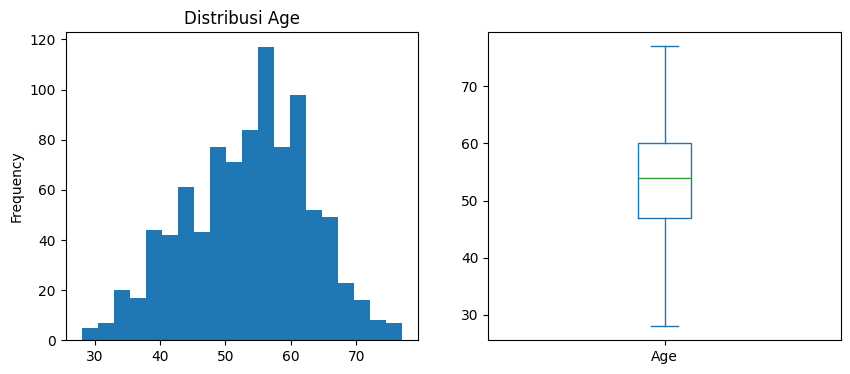

Skewness Age: -0.20


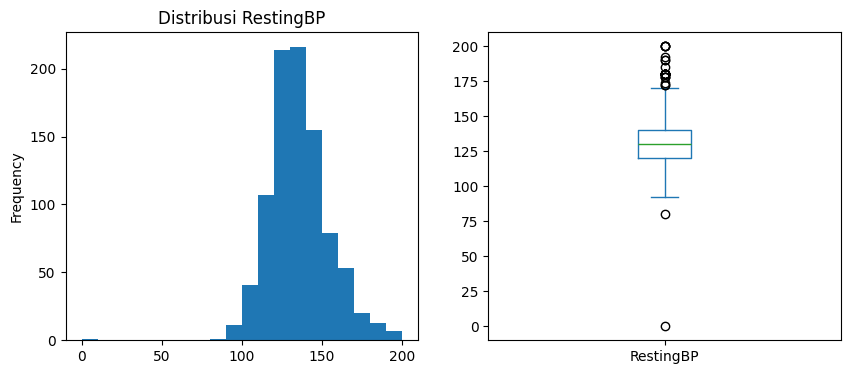

Skewness RestingBP: 0.18


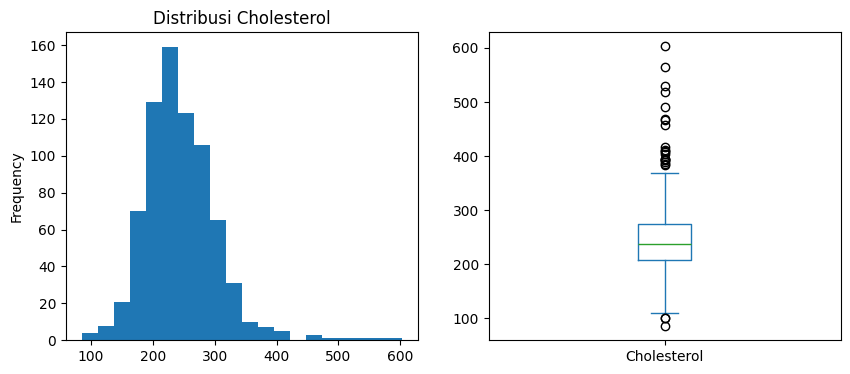

Skewness Cholesterol: 1.24


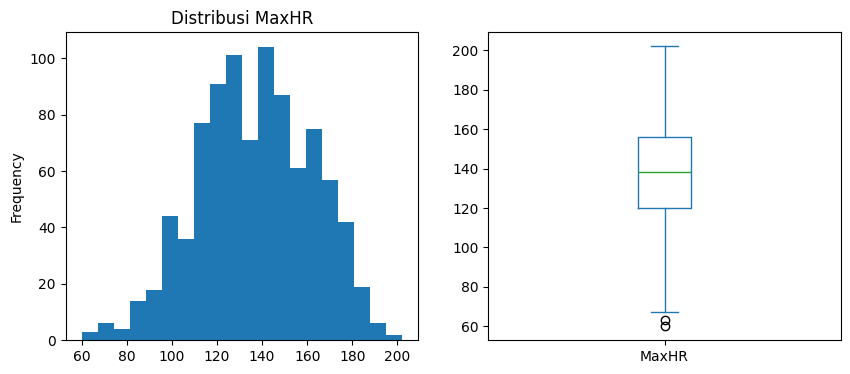

Skewness MaxHR: -0.14


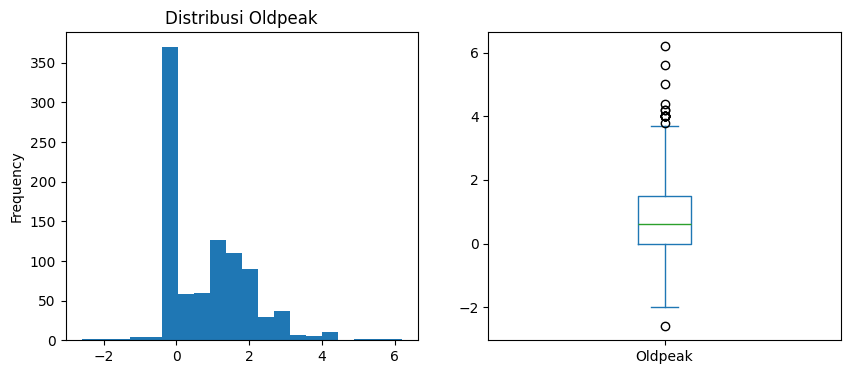

Skewness Oldpeak: 1.02


In [10]:
for col in num_cols:
    fig, ax = plt.subplots(ncols=2, figsize=(10, 4))
    df_eda[col].plot(kind='hist', bins=20, ax=ax[0])   # histogram
    df_eda[col].plot(kind='box', ax=ax[1])             # boxplot
    ax[0].set_title(f'Distribusi {col}')
    plt.show()
    print(f"Skewness {col}: {df_eda[col].skew():.2f}")

**Insight:**
- `Age` dan `MaxHR` distribusinya hampir simetris. `Age` tidak punya outlier (rentang 28-77 tahun), `MaxHR` hanya 2 outlier di sisi bawah.
- `Cholesterol` (tanpa nilai 0) miring ke kanan (skewness 1.24) dengan 23 outlier, sebagian besar bernilai tinggi hingga 603 mg/dl. Median (237) lebih rendah dari mean (244.6). 
- `Oldpeak` miring ke kanan (skewness 1.02) dengan 16 outlier, hampir semuanya di atas. 
- Karena `Cholesterol` miring, imputasi sebaiknya memakai median, bukan mean. Outlier pada `Cholesterol` dan `Oldpeak` masih masuk akal secara klinis, jadi tidak dihapus.

### 2. Korelasi feature dan target
 Kolom mana yang paling berhubungan dengan target, dan apakah ada fitur yang saling berkorelasi tinggi.

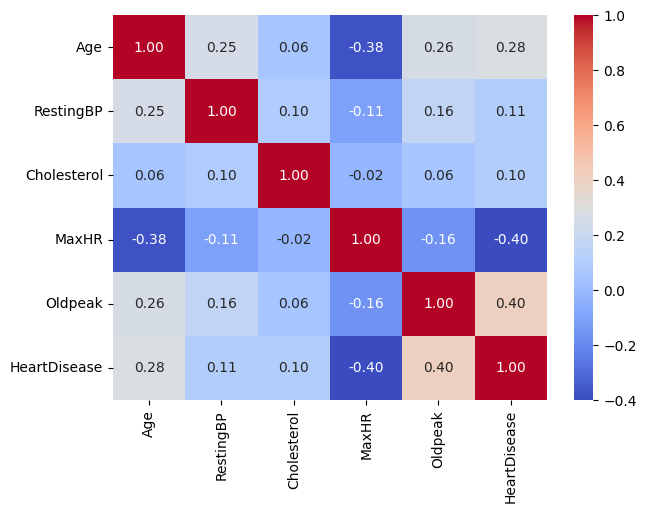

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_eda[num_cols + ['HeartDisease']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

**Insight:**
- Korelasi tertinggi dengan target adalah `Oldpeak` (0.40) dan `MaxHR` (-0.40), disusul `Age` (0.28). `RestingBP` (0.11) dan `Cholesterol` (0.10) lemah.
- Korelasi antar fitur tertinggi hanya `Age` dan `MaxHR` (-0.38), sisanya di bawah 0.3,
- Korelasi tertinggi hanya sekitar 0.4, sehingga hubungan numerik-target moderat. Fitur kategorikal mungkin berperan besar.

### EDA kategorikal

### 3. Distribusi tiap kategori
Apakah ada kategori yang sangat dominan atau sangat sedikit

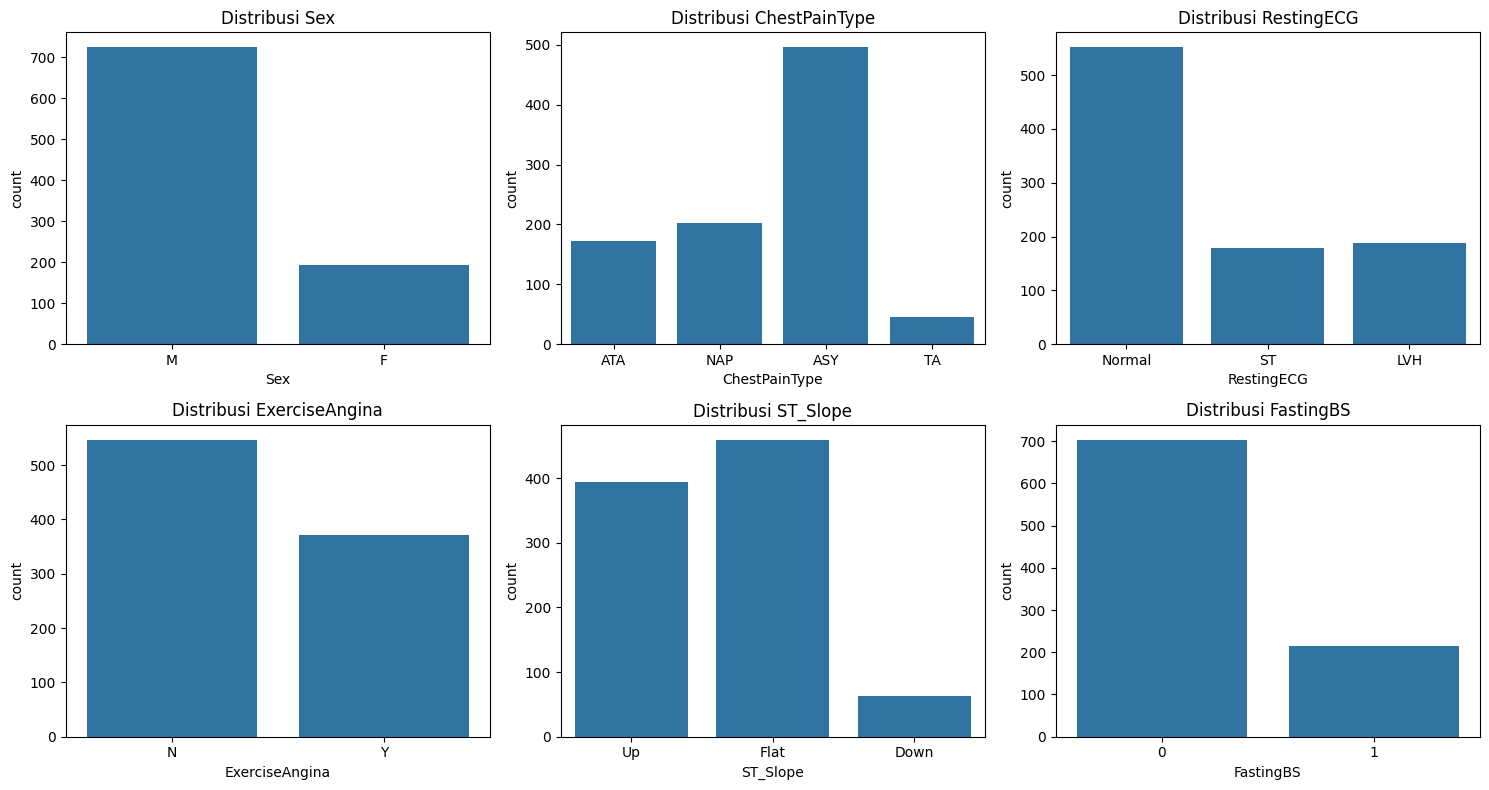

In [12]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'FastingBS']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=df, x=col, ax=ax)      # jumlah per kategori
    ax.set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

**Insight: distribusi fitur kategorikal**
- `Sex`: didominasi laki-laki (M), sedangkan perempuan (F) hanya sisanya
- `ChestPainType`: tipe ASY paling banyak, disusul NAP dan ATA. Tipe TA paling sedikit.
- `RestingECG`: kategori Normal paling banyak, sedangkan ST dan LVH jumlahnya hampir sama
- `ExerciseAngina`: relatif seimbang
- `ST_Slope`: Flat dan Up mendominasi, sedangkan Down sangat sedikit
- `FastingBS`: condong ke 0 dibanding 1 
- Secara keseluruhan, `Sex` paling timpang dan `ExerciseAngina` paling seimbang. Beberapa kategori jumlah datanya jauh lebih sedikit dari yang lain, yaitu `TA`, `Down`, dan perempuan (`F`)

### 4. Uji Chi-Squared
P-value di bawah 0,05 berarti ada hubungan yang signifikan secara statistik antara kategori itu dan target.

In [13]:
for col in cat_cols:
    ct = pd.crosstab(df[col], df['HeartDisease'])
    res = stats.chi2_contingency(ct)
    print(f"{col}: p={res.pvalue:.2e}")


Sex: p=4.60e-20
ChestPainType: p=8.08e-58
RestingECG: p=4.23e-03
ExerciseAngina: p=2.91e-50
ST_Slope: p=5.17e-78
FastingBS: p=1.06e-15


**Uji hipotesis (chi-square)**
- H0: fitur kategorikal dan `HeartDisease` saling independen (tidak ada hubungan)
- H1: fitur kategorikal dan `HeartDisease` tidak independen (ada hubungan)

**Insight:**
- Semua fitur kategorikal punya p-value < 0.05, sehingga H0 ditolak untuk semuanya
- P-value terkecil ada pada `ST_Slope`, `ChestPainType`, dan `ExerciseAngina`.`RestingECG` paling besar, tapi masih di bawah 0.05
- Artinya `ChestPainType`, `ST_Slope`, dan `ExerciseAngina` paling kuat membedakan pasien sakit dan sehat, sedangkan `RestingECG` paling lemah dan kemungkinan kurang berpengaruh pada model
- Uji ini hanya menunjukkan adanya hubungan dan bukan sebab-akibat

## Feature Engineering

### Split between Numeric and Categorical 

In [14]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
nom_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
bin_cols = ['FastingBS']

### Cardinality

In [15]:
for col in nom_cols:
    print(f"Cardinality {col}: {df[col].nunique()}")

Cardinality Sex: 2
Cardinality ChestPainType: 4
Cardinality RestingECG: 3
Cardinality ExerciseAngina: 2
Cardinality ST_Slope: 3


Semua fitur kategorikal hanya memiliki 2-4 kategori, sehingga tidak ada high cardinality
dan tidak perlu pengelompokan kategori. Encoding langsung menggunakan OneHotEncoder.

### Nilai 0 yang mustahil jadi NaN

In [16]:
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)

### Split features and target

In [17]:
X = df.drop(columns='HeartDisease')
y = df['HeartDisease']
X

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up
...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110.0,264.0,0,Normal,132,N,1.2,Flat
914,68,M,ASY,144.0,193.0,1,Normal,141,N,3.4,Flat
915,57,M,ASY,130.0,131.0,0,Normal,115,Y,1.2,Flat
916,57,F,ATA,130.0,236.0,0,LVH,174,N,0.0,Flat


### Train-test split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train Size', X_train.shape)
print('Test Size', X_test.shape)

Train Size (734, 11)
Test Size (184, 11)


### Outlier handling

In [19]:
#check distribution form skewness
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

listItem= []

for col in num_cols:
  listItem.append([col, round(X_train[col].skew(),1), np.where(
    (round(X_train[col].skew(),1) <= 0.5) & (round(X_train[col].skew(),1) >= -0.5),
    'normal',
    'skewed')])



skewness = pd.DataFrame(columns=['nama kolom', 'nilai skewness', 'distribution'], data= listItem)
skewness

,nama kolom,nilai skewness,distribution
0,Age,-0.2,normal
1,RestingBP,0.6,skewed
2,Cholesterol,1.2,skewed
3,MaxHR,-0.2,normal
4,Oldpeak,1.0,skewed


In [20]:
# Get upper, lower boundaries and percentage of outliers
fold = 1.5  # 1.5 = mild outlier, 3 = extreme outlier

column = []
lower_bound = []
upper_bound = []
percent_total_outlier = []

for row in range(0, len(skewness)):
    col = skewness['nama kolom'][row]

    # checking upper and lower boundary
    if skewness['distribution'][row] == 'skewed':
        IQR = X_train[col].quantile(0.75) - X_train[col].quantile(0.25)
        lower_boundary = X_train[col].quantile(0.25) - (IQR * fold)
        upper_boundary = X_train[col].quantile(0.75) + (IQR * fold)
    else:
        lower_boundary = X_train[col].mean() - 3 * X_train[col].std()
        upper_boundary = X_train[col].mean() + 3 * X_train[col].std()
    # append to list
    column.append(col)
    lower_bound.append(lower_boundary)
    upper_bound.append(upper_boundary)

    is_outlier = (X_train[col] > upper_boundary) | (X_train[col] < lower_boundary)
    percent_total_outlier.append(is_outlier.mean() * 100)

outliers = pd.DataFrame({
    'column': column,
    'upper_boundary': np.round(upper_bound, 2),
    'lower_boundary': np.round(lower_bound, 2),
    'percentage_total_outlier': np.round(percent_total_outlier, 2)
})
outliers

,column,upper_boundary,lower_boundary,percentage_total_outlier
0,Age,82.17,25.53,0.00
1,RestingBP,172.50,88.50,2.72
2,Cholesterol,377.50,109.50,2.72
3,MaxHR,213.87,58.88,0.00
4,Oldpeak,3.75,-2.25,1.77


**Insight:**
- Dengan batas 1.5×IQR untuk kolom skewed dan mean ± 3 std untuk kolom
  berdistribusi normal, outlier ditemukan pada `Cholesterol` dan
  `Oldpeak`. `Age`, `RestingBP`, dan `MaxHR` tidak memiliki outlier
  yang signifikan 
- Outlier `Cholesterol` dan outlier `Oldpeak` berada di atas 3 (maksimum 6.2). Kedua     nilai ini masih masuk akal secara klinis dan justru bisa mencerminkan pasien berisiko tinggi, sehingga **bukan kesalahan input**.
- Nilai 0 pada `Cholesterol` dan `RestingBP` **bukan outlier**, melainkan
  missing value yang tidak mungkin secara medis. Kasus ini ditangani lewat
  imputasi.
- `FastingBS` tidak dihitung karena merupakan variabel biner.
- Karena outlier bernilai wajar dan jumlah data kecil (918 baris),
  outlier tidak dihapus, tetapi ditangani dengan **capping (winsorizing)**.

In [21]:
# kolom skewed -> IQR fold 1.5
capper_skewed = Winsorizer(capping_method='iqr', tail='both', fold=1.5,
                           variables=['Cholesterol', 'Oldpeak'],
                           missing_values='ignore')

# kolom normal -> mean ± 3 std (gaussian)
capper_normal = Winsorizer(capping_method='gaussian', tail='both', fold=3,
                           variables=['Age', 'RestingBP', 'MaxHR'],
                           missing_values='ignore')

# fit di train saja, lalu transform train & test
X_train_capped = capper_normal.fit_transform(capper_skewed.fit_transform(X_train))
X_test_capped = capper_normal.transform(capper_skewed.transform(X_test))

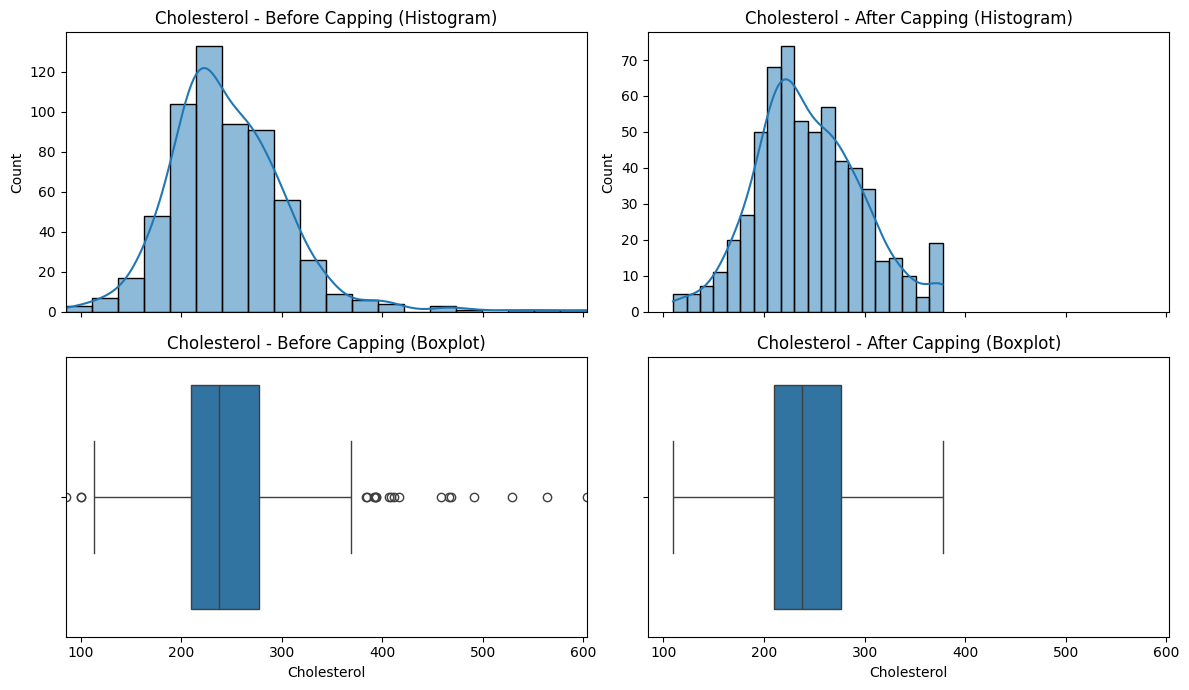

Skewness Cholesterol: before = 1.24, after = 0.31


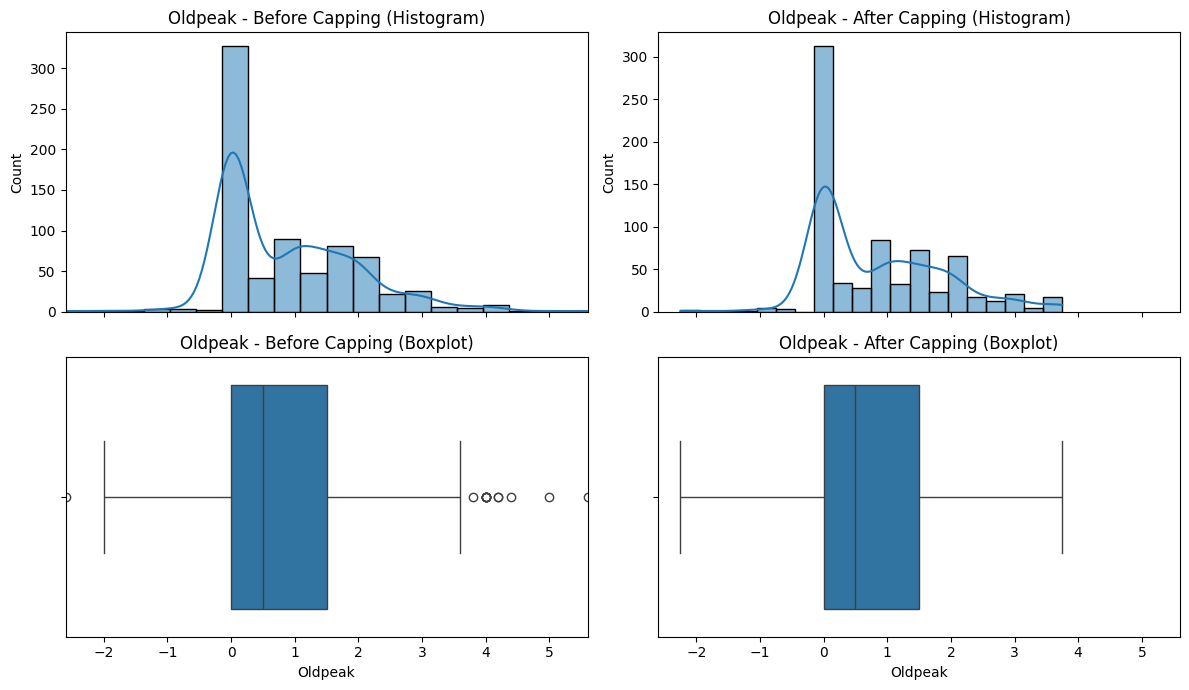

Skewness Oldpeak: before = 0.95, after = 0.80


In [22]:
cols_to_plot = ['Cholesterol', 'Oldpeak']   # kolom yang kena capping

for col in cols_to_plot:
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex='col')

    # Histogram
    sns.histplot(X_train[col], bins=20, kde=True, ax=axes[0, 0])
    axes[0, 0].set_title(f'{col} - Before Capping (Histogram)')

    sns.histplot(X_train_capped[col], bins=20, kde=True, ax=axes[0, 1])
    axes[0, 1].set_title(f'{col} - After Capping (Histogram)')

    # Boxplot
    sns.boxplot(x=X_train[col], ax=axes[1, 0])
    axes[1, 0].set_title(f'{col} - Before Capping (Boxplot)')

    sns.boxplot(x=X_train_capped[col], ax=axes[1, 1])
    axes[1, 1].set_title(f'{col} - After Capping (Boxplot)')

    # samakan rentang x antara before dan after
    xmin = min(X_train[col].min(), X_train_capped[col].min())
    xmax = max(X_train[col].max(), X_train_capped[col].max())
    for ax in axes.flat:
        ax.set_xlim(xmin, xmax)

    plt.tight_layout()
    plt.show()

    print(f"Skewness {col}: before = {X_train[col].skew():.2f}, "
          f"after = {X_train_capped[col].skew():.2f}")

**Insight (Before vs After Capping):**
- Setelah capping, titik outlier pada boxplot `Cholesterol` dan `Oldpeak`
  berkurang karena nilai ekstrem ditarik ke batas atas/bawah
- Bentuk distribusi secara umum masih sama (masih miring ke kanan),
  tetapi ekornya lebih pendek sehingga lebih stabil 
- Jumlah baris tidak berubah, tidak ada data yang hilang

### Missing values handling

Missing values setelah nilai `0` yang mustahil diubah menjadi `NaN` akan di imputasi menggunakan **SimpleImputer** di **ColumnTransformer**

### Feature selection

In [23]:
hasil = []
for col in num_cols:
    # hitung korelasi tiap kolom numerik dengan target (baris NaN dibuang dulu)
    mask = X_train[col].notna()
    r, p = pearsonr(X_train.loc[mask, col], y_train[mask])
    hasil.append({'kolom': col, 'r': round(r, 3), 'p_value': p,
                  'hasil': 'ada korelasi' if p < 0.05 else 'tidak ada korelasi'})
pd.DataFrame(hasil)

,kolom,r,p_value,hasil
0,Age,0.245,1.812908e-11,ada korelasi
1,RestingBP,0.102,5.650109e-03,ada korelasi
2,Cholesterol,0.081,4.564678e-02,ada korelasi
3,MaxHR,-0.407,1.084541e-30,ada korelasi
4,Oldpeak,0.377,3.784657e-26,ada korelasi


### Column transformer

In [24]:
# cell Column transformer: nested Pipeline per tipe kolom (gaya materi End-to-End)
preprocessing = ColumnTransformer([
    ('numerical', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),   # Cholesterol & RestingBP skewed/NaN
        ('scaler', StandardScaler())
    ]), num_cols),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), nom_cols + bin_cols)
])

In [25]:
# preprocessing kolom numerik: isi NaN dengan median (data skewed), lalu scaling
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),   # median tahan terhadap outlier
    ('scaler', StandardScaler())                     # samakan skala (penting untuk KNN & SVM)
])

# preprocessing kolom kategorikal: isi NaN dengan modus, lalu one-hot encoding
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),     # isi dengan kategori terbanyak
    ('encoder', OneHotEncoder(handle_unknown='ignore'))       # abaikan kategori baru saat inference
])

# gabungkan: numerik ke num_pipe, nominal + biner ke cat_pipe
preprocessing = ColumnTransformer([
    ('numerical', num_pipe, num_cols),               # 5 kolom numerik kontinu
    ('categorical', cat_pipe, nom_cols + bin_cols)   # 5 nominal + FastingBS
])

## Model definition

**Algoritma yang digunakan**
- **KNN**: klasifikasi berdasarkan kemiripan dengan pasien lain
- **SVM**: bagus untuk data berdimensi kecil
- **Decision Tree**: mudah diinterpretasi ke tenaga medis
- **Random Forest**: bagging dari banyak tree
- **XGBoost**: boosting, tree dibangun berurutan memperbaiki kesalahan tree sebelumnya

**Hyperparameter**: semua memakai nilai default (baseline), kecuali `random_state=42` agar hasil
reproducible. Tuning dilakukan nanti pada model terbaik.

**Metrics**: **Recall** sebagai metrik utama, karena pasien sakit jantung yang terprediksi sehat
(False Negative) lebih berbahaya daripada sebaliknya. **F1-score** sebagai pendamping agar
precision tidak diabaikan.

In [26]:
# fungsi pembuat pipeline lengkap: capping outlier -> preprocessing -> model
def make_pipe(model):
    # capping kolom skewed dengan metode IQR (fit hanya pada data train)
    capper_skewed = Winsorizer(capping_method='iqr', tail='both', fold=1.5,
                               variables=[ 'Cholesterol', 'Oldpeak'],
                               missing_values='ignore')
    # capping kolom normal dengan metode gaussian (mean ± 3 std)
    capper_normal = Winsorizer(capping_method='gaussian', tail='both', fold=3,
                               variables=['Age', 'MaxHR', 'RestingBP'],
                               missing_values='ignore')
    # capping -> column transformer -> model
    return Pipeline([
        ('capper_skewed', capper_skewed),    # langkah 1: capping kolom skewed
        ('capper_normal', capper_normal),    # langkah 2: capping kolom normal
        ('transformer', preprocessing),      # langkah 3: imputasi, scaling, encoding
        ('classifier', model)                # langkah 4: algoritma klasifikasi
    ])

# pipeline untuk tiap algoritma (hyperparameter default)
pipe_knn = make_pipe(KNeighborsClassifier())                          # K-Nearest Neighbors
pipe_svm = make_pipe(SVC(random_state=42))                            # Support Vector Machine
pipe_dt  = make_pipe(DecisionTreeClassifier(random_state=42))         # Decision Tree
pipe_rf  = make_pipe(RandomForestClassifier(random_state=42))         # Random Forest
pipe_xgb = make_pipe(XGBClassifier(random_state=42))                  # XGBoost (boosting)

# kumpulkan dalam dictionary agar mudah di-loop saat training dan cross validation
pipelines = {'KNN': pipe_knn, 'SVM': pipe_svm, 'Decision Tree': pipe_dt,
             'Random Forest': pipe_rf, 'XGBoost': pipe_xgb}

`RestingBP` memiliki skewness 0.6, hanya sedikit di atas batas 0.5 (borderline), sehingga
diperlakukan mendekati normal dan di-capping dengan metode gaussian (mean ± 3 std).
Outlier-nya sangat sedikit dan nilainya masih wajar secara klinis.

## Base model training

In [27]:
# latih semua pipeline pada data train mentah (capping, imputasi, scaling, encoding ikut di dalam pipeline)
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)   # fit pipeline ke data train
    print(f'{name} selesai dilatih')   # tanda model sudah terlatih

KNN selesai dilatih
SVM selesai dilatih
Decision Tree selesai dilatih
Random Forest selesai dilatih
XGBoost selesai dilatih


## Model evaluation

In [28]:
# cross validation 5-fold stratified agar proporsi kelas tiap fold sama
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hasil_cv = []   # tempat menyimpan hasil tiap model
for name, pipe in pipelines.items():
    # hitung recall, f1, dan precision di tiap fold, termasuk skor train untuk cek overfitting
    cv = cross_validate(pipe, X_train, y_train, cv=skf,
                        scoring=['recall', 'f1', 'precision'], return_train_score=True)
    hasil_cv.append({
        'model': name,                                          # nama algoritma
        'recall_mean': cv['test_recall'].mean(),                # rata-rata recall validasi
        'recall_std': cv['test_recall'].std(),                  # stabilitas recall antar fold
        'f1_mean': cv['test_f1'].mean(),                        # rata-rata f1 validasi
        'precision_mean': cv['test_precision'].mean(),          # rata-rata precision validasi
        'recall_train': cv['train_recall'].mean()               # recall di data train (deteksi overfit)
    })

# tampilkan tabel, urut dari recall validasi tertinggi
df_cv = pd.DataFrame(hasil_cv).sort_values('recall_mean', ascending=False).round(3)
df_cv

,model,recall_mean,recall_std,f1_mean,precision_mean,recall_train
1,SVM,0.899,0.021,0.875,0.854,0.924
3,Random Forest,0.889,0.057,0.874,0.865,1.000
4,XGBoost,0.877,0.017,0.870,0.863,1.000
0,KNN,0.869,0.026,0.860,0.852,0.911
2,Decision Tree,0.805,0.063,0.812,0.823,1.000


**Insight (Cross Validation Baseline):**
- **SVM** terbaik dengan recall tertinggi (0.899), std kecil (0.021), dan gap train-validasi paling kecil
  (0.924 vs 0.899), artinya paling stabil dan tidak overfitting
- **Random Forest** dan **XGBoost** punya recall train 1.000 sedangkan recall validasinya 0.889 dan 0.877,
  jadi keduanya **overfitting**. Std Random Forest juga besar (0.057), sehingga performanya kurang konsisten antar fold
- **KNN** cukup stabil tetapi recall-nya sedikit di bawah SVM (0.869)
- **Decision Tree** terburuk: recall validasi hanya 0.805, std besar (0.063), dan recall train 1.000,
  tanda overfitting paling parah karena satu tree mudah menghafal data train
- Recall dijadikan metrik utama karena kesalahan terburuk adalah pasien sakit jantung yang terprediksi sehat
  (False Negative)
- **SVM dipilih untuk hyperparameter tuning** karena recall tertinggi dan paling stabil

## Hyperparameter tuning

In [29]:
param_svm = {
    'transformer__numerical__scaler': [StandardScaler(), MinMaxScaler()],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': ['scale', 0.01, 0.1]
}
grid_svm = GridSearchCV(pipe_svm, param_svm, cv=skf, scoring='recall',
                        return_train_score=True, n_jobs=-1).fit(X_train, y_train)
best_pipe_svm = grid_svm.best_estimator_
print(grid_svm.best_params_, grid_svm.best_score_)

{'classifier__C': 0.1, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf', 'transformer__numerical__scaler': MinMaxScaler()} 0.9385124962360735


In [30]:
for name, m in {'baseline': pipe_svm, 'tuned': best_pipe_svm}.items():
    p = m.predict(X_test)
    print(name, recall_score(y_test, p), f1_score(y_test, p))

baseline 0.9019607843137255 0.8846153846153846
tuned 0.9215686274509803 0.9038461538461539


## Model saving

In [31]:
with open('model_svm.pkl', 'wb') as f:
    pickle.dump(best_pipe_svm, f)


## Kesimpulan 
**Model Terbaik:** **SVM**. Pada cross validation, SVM unggul di antara lima algoritma dengan recall 0.899, std paling kecil (0.021) dan selisih train validasi tertipis. Sisanya **overfit**

### Kelemahan dan perbaikan
- Langkah `0` → `NaN` untuk `Cholesterol` dan `RestingBP` (cell 31) ada di luar pipeline, jadi model yang tersimpan tidak tahu soal itu.
**Fix:** Saat inference atau deployment, isi np.nan untuk nilai yang tidak diketahui. Kalau diisi 0, pipeline menganggapnya nilai asli dan tidak meng-impute dengan median. Alternatifnya, pindahkan langkah itu ke dalam pipeline.
- Tidak ada **confusion matrix**, **precision** dan **specificity di data test. Tambahkan agar lebih akurat penilaiannya
- Data `Sex` M dan F tidak seimbang dan **sangat imbalance**. Performa pada perempuan belum tentu sama